In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

from matplotlib.gridspec import GridSpec
import h5py, glob
from os.path import join as pjoin


In [3]:
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

# mouse='cm229'
# h5_root = step_3_root+mouse+'/dlc_h5s/'
# mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'


data_root =  str(PREPARES / "epochs-rest-to-running") + "/"


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import h5py, glob
from os.path import join as pjoin
from scipy import stats

# paths and helpers (load_pickle, normalize, time_in_each_roi) assumed defined

def parse_session(session_name):
    """'cm229_1_runC' -> ('cm229','1','runC','229','C')"""
    mouse, day, run = session_name.split('_')
    numeric = mouse.replace('cm', '')
    return mouse, day, run, numeric, run[-1]


def load_session_data(session_name):
    mouse, day, run, numeric, run_letter = parse_session(session_name)
    mouse_day = f'{mouse}_{day}'

    # --- mouse-specific indices ---
    M2_ind      = load_pickle(fetch_path_M2 + 'brightest_frontline_ind-' + mouse)
    sensory_ind = load_pickle(fetch_path_S1 + 'brightest_ind_' + mouse)
    if mouse == 'cm229':
        M1_RFP_ind = 322
    elif mouse == 'cm219':
        M1_RFP_ind = 315
    else:
        raise ValueError(f'Unknown mouse {mouse}')

    # --- H matrix (step_2) ---
    fname_H = list(set(glob.glob(
        step_2_root + f"*{numeric}/{day}/H_*[{run_letter}]*.mat")))[0]
    with h5py.File(fname_H, 'r') as f_H:
        H       = np.array(f_H['H']).transpose()[:, 500:-505]
        H_gcamp = np.array(f_H['H_gcamp']).transpose()[:, 500:-505]

    # --- front-camera DLC (paw velocity) ---
    h5_root = step_3_root + mouse + '/dlc_h5s/'
    f_name_dlc = glob.glob(h5_root + mouse_day + '_' + run + '*h5')[0]
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0]
    new_df = Dataframe[scorer]

    paws_vel_df = pd.DataFrame()
    for bpt in ['LFP', 'RFP']:
        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(
            np.vstack([new_df[bpt]['x'].values.flatten(),
                       new_df[bpt]['y'].values.flatten()]).T)
        vel_smooth = pd.DataFrame(vel).rolling(80).std()
        vel        = pd.DataFrame(vel).rolling(40).std()
        tocut = vel.shape[0] % 4
        if tocut == 0:
            vel        = np.mean(vel.values.reshape((-1, 4)), axis=1)
            vel_smooth = np.mean(vel_smooth.values.reshape((-1, 4)), axis=1)
        else:
            vel        = np.mean(vel[:-tocut].values.reshape((-1, 4)), axis=1)
            vel_smooth = np.mean(vel_smooth[:-tocut].values.reshape((-1, 4)), axis=1)
        paws_vel_df[bpt] = vel_smooth[500:-505]

    RFP_vel     = stats.zscore(np.array(paws_vel_df['RFP']))
    log_RFP_vel = stats.zscore(np.log(1 + np.array(paws_vel_df['RFP'])))

    # --- cam PC (face / body) ---
    if mouse == 'cm219':
        cam_pc_path = pjoin(step_3_root, mouse, day, run + '_cam1_pc.mat')
    else:
        cam_pc_path = pjoin(step_3_root, mouse, day, run + '_cam_pc.mat')
        
    with h5py.File(cam_pc_path, 'r') as f_b:
        
        motionS = f_b['motionS']
        motion_pc = {}
        for key in list(motionS.keys()):
            arr = pd.DataFrame(motionS[key]).transpose()
            ss = arr.shape
            tocut = ss[1] % 4
            if tocut == 0:
                arr = np.mean(arr.values.reshape((ss[0], ss[1]//4, 4)), axis=2)
            else:
                arr = np.mean(arr.iloc[:, :-tocut].values.reshape((ss[0], -1, 4)), axis=2)
            arr = pd.DataFrame(arr).T.rolling(window=5).std().T
            motion_pc[key] = arr.iloc[:, 500:-505]

    face_pc = stats.zscore(np.array(motion_pc['face'].iloc[:200, :].mean(axis=0)))
    body_pc = stats.zscore(np.array(motion_pc['body'].iloc[:200, :].mean(axis=0)))

    # clip extremes
    thr = 5
    for arr in (face_pc, body_pc, RFP_vel, log_RFP_vel):
        arr[arr > thr] = thr

    # --- build trace dicts from H using indices ---
    choice_dict = {'RFP_S1': sensory_ind['RFP'],
                   'RFP_M1': M1_RFP_ind,
                   'RFP_M2': M2_ind['RFP']}
    jrgeco2plot = {k: H[i, :]       for k, i in choice_dict.items()}
    gcamp2plot  = {k: H_gcamp[i, :] for k, i in choice_dict.items()}

# --- align all streams to the shortest length ---
    min_len = min(H.shape[-1], H_gcamp.shape[-1],
                  len(face_pc), len(body_pc),
                  len(RFP_vel), len(log_RFP_vel))

    jrgeco2plot = {k: v[:min_len] for k, v in jrgeco2plot.items()}
    gcamp2plot  = {k: v[:min_len] for k, v in gcamp2plot.items()}
    behaviors = {'face_pc':     face_pc[:min_len],
                 'log_RFP_vel': log_RFP_vel[:min_len],
                 'RFP_vel':     RFP_vel[:min_len],
                 'body_pc':     body_pc[:min_len]}

    return {'session_name': session_name,
            'mouse': mouse,
            'jrgeco2plot': jrgeco2plot,
            'gcamp2plot':  gcamp2plot,
            'behaviors':   behaviors,
            'n_frames':    min_len}

In [6]:
sd1 = load_session_data('cm219_3_runF')
sd2 = load_session_data('cm229_1_runC')
print(f"{sd1['session_name']}: {sd1['n_frames']} frames ({sd1['n_frames']/15:.1f} s)")
print(f"{sd2['session_name']}: {sd2['n_frames']} frames ({sd2['n_frames']/15:.1f} s)")

cm219_3_runF: 9205 frames (613.7 s)
cm229_1_runC: 7973 frames (531.5 s)


### Preview full sessions to pick a time window

This cell plots both full sessions stacked with a time axis in seconds so you can eyeball where the interesting segments are. Grid lines every 10 s.

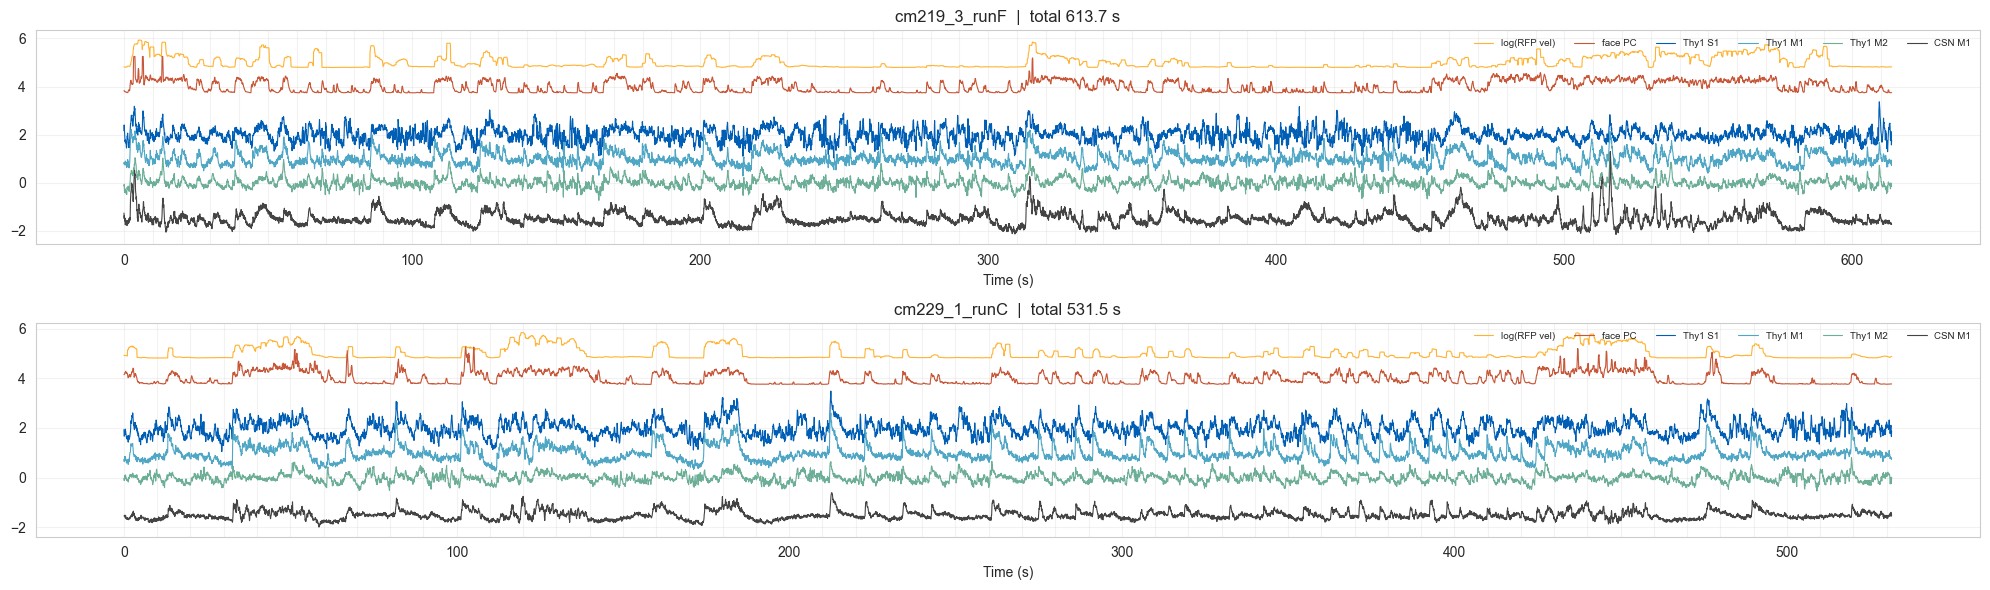

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(20, 6), dpi=100, sharex=False)

for ax, sd in zip(axes, [sd1, sd2]):
    t = np.arange(sd['n_frames']) / 15.0
    ax.plot(t, sd['behaviors']['log_RFP_vel']/4 + 5, color='#ffb332',  lw=0.8, label='log(RFP vel)')
    ax.plot(t, sd['behaviors']['face_pc']    /4 + 4, color='#c75738',  lw=0.8, label='face PC')
    ax.plot(t, sd['jrgeco2plot']['RFP_S1']*12 + 2,   color='#015EB5', lw=0.8, label='Thy1 S1')
    ax.plot(t, sd['jrgeco2plot']['RFP_M1']*12 + 1,   color='#4fa7c5', lw=0.8, label='Thy1 M1')
    ax.plot(t, sd['jrgeco2plot']['RFP_M2']*12 + 0,   color='#6dae96', lw=0.8, label='Thy1 M2')
    ax.plot(t, sd['gcamp2plot']['RFP_M1']*12 - 1.5,  color='#444444', lw=0.8, label='CSN M1')
    ax.set_title(f"{sd['session_name']}  |  total {sd['n_frames']/15:.1f} s")
    ax.set_xlabel('Time (s)')
    ax.legend(loc='upper right', fontsize=7, ncol=6, frameon=False)
    ax.set_xticks(np.arange(0, t[-1], 10), minor=True)
    ax.grid(True, which='both', alpha=0.25)

plt.tight_layout()
plt.show()

### Select window + sanity check preview

In [8]:
t_start_sec_1 = 237.0     # cm219_3_runF start (seconds)
t_start_sec_2 = 198.0     # cm229_1_runC start (seconds)
window_sec    = 90.0    # common window length (seconds)

Total window: 90.0 s (1350 frames)
cm219 breaks at: [35.0] s
cm229 breaks at: [] s


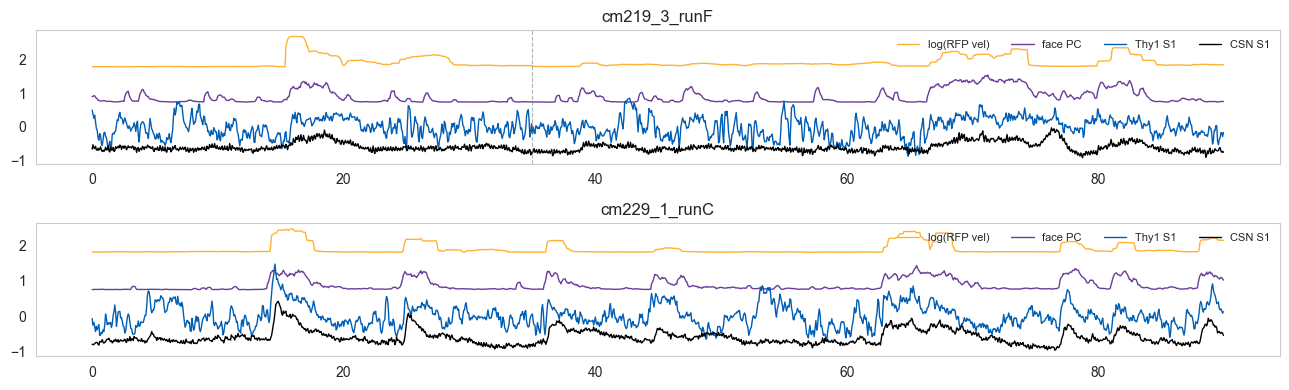

In [9]:
# --- segments per mouse: list of (start_sec, end_sec) tuples ---
# Use ONE tuple for a single continuous window, or MULTIPLE to concatenate.
segments_1 = [(237.0, 267.0), (237.0, 267.0), (300.0, 315.0)]   # cm219_3_runF — 30 + 60 = 90 s
segments_1 = [(70,105),(135, 190)]
segments_2 = [(198.0, 288.0)]                    # cm229_1_runC — 90 s
# --------------------------------------------------------------

FS = 15.0

def segments_to_indices(segments, fs=FS):
    chunks = [np.arange(int(round(s0*fs)), int(round(s1*fs)))
              for s0, s1 in segments]
    return np.concatenate(chunks)

def segments_breaks(segments):
    """Time (in concatenated seconds) where each break occurs."""
    out, cum = [], 0.0
    for s0, s1 in segments[:-1]:
        cum += (s1 - s0)
        out.append(cum)
    return out

idx_slice_1 = segments_to_indices(segments_1)
idx_slice_2 = segments_to_indices(segments_2)
breaks_1    = segments_breaks(segments_1)
breaks_2    = segments_breaks(segments_2)

# sanity checks
assert idx_slice_1.max() < sd1['n_frames'], 'cm219 segments exceed session length'
assert idx_slice_2.max() < sd2['n_frames'], 'cm229 segments exceed session length'
assert len(idx_slice_1) == len(idx_slice_2), \
    f'mismatched lengths: cm219={len(idx_slice_1)}, cm229={len(idx_slice_2)}'

window_length = len(idx_slice_1)
window_sec    = window_length / FS
print(f"Total window: {window_sec:.1f} s ({window_length} frames)")
print(f"cm219 breaks at: {breaks_1} s")
print(f"cm229 breaks at: {breaks_2} s")

# quick overlay to confirm the cuts
fig, axes = plt.subplots(2, 1, figsize=(13, 4), dpi=100)
for ax, sd, idx_slice, breaks in zip(
        axes, [sd1, sd2], [idx_slice_1, idx_slice_2], [breaks_1, breaks_2]):
    t = np.arange(len(idx_slice)) / FS
    ax.plot(t, sd['behaviors']['log_RFP_vel'][idx_slice]/4 + 2, color='#ffb332', lw=1, label='log(RFP vel)')
    ax.plot(t, sd['behaviors']['face_pc'][idx_slice]    /4 + 1, color='#6A3D9A', lw=1, label='face PC')
    ax.plot(t, sd['jrgeco2plot']['RFP_S1'][idx_slice]*12,       color='#015EB5', lw=1, label='Thy1 S1')
    ax.plot(t, sd['gcamp2plot']['RFP_S1'][idx_slice]*12 - 0.6,  color='black',   lw=1, label='CSN S1')
    for bx in breaks:
        ax.axvline(bx, color='gray', linestyle='--', lw=0.8, alpha=0.6)
    ax.set_title(sd['session_name'])
    ax.legend(loc='upper right', fontsize=8, ncol=4, frameon=False)
plt.tight_layout()
plt.show()

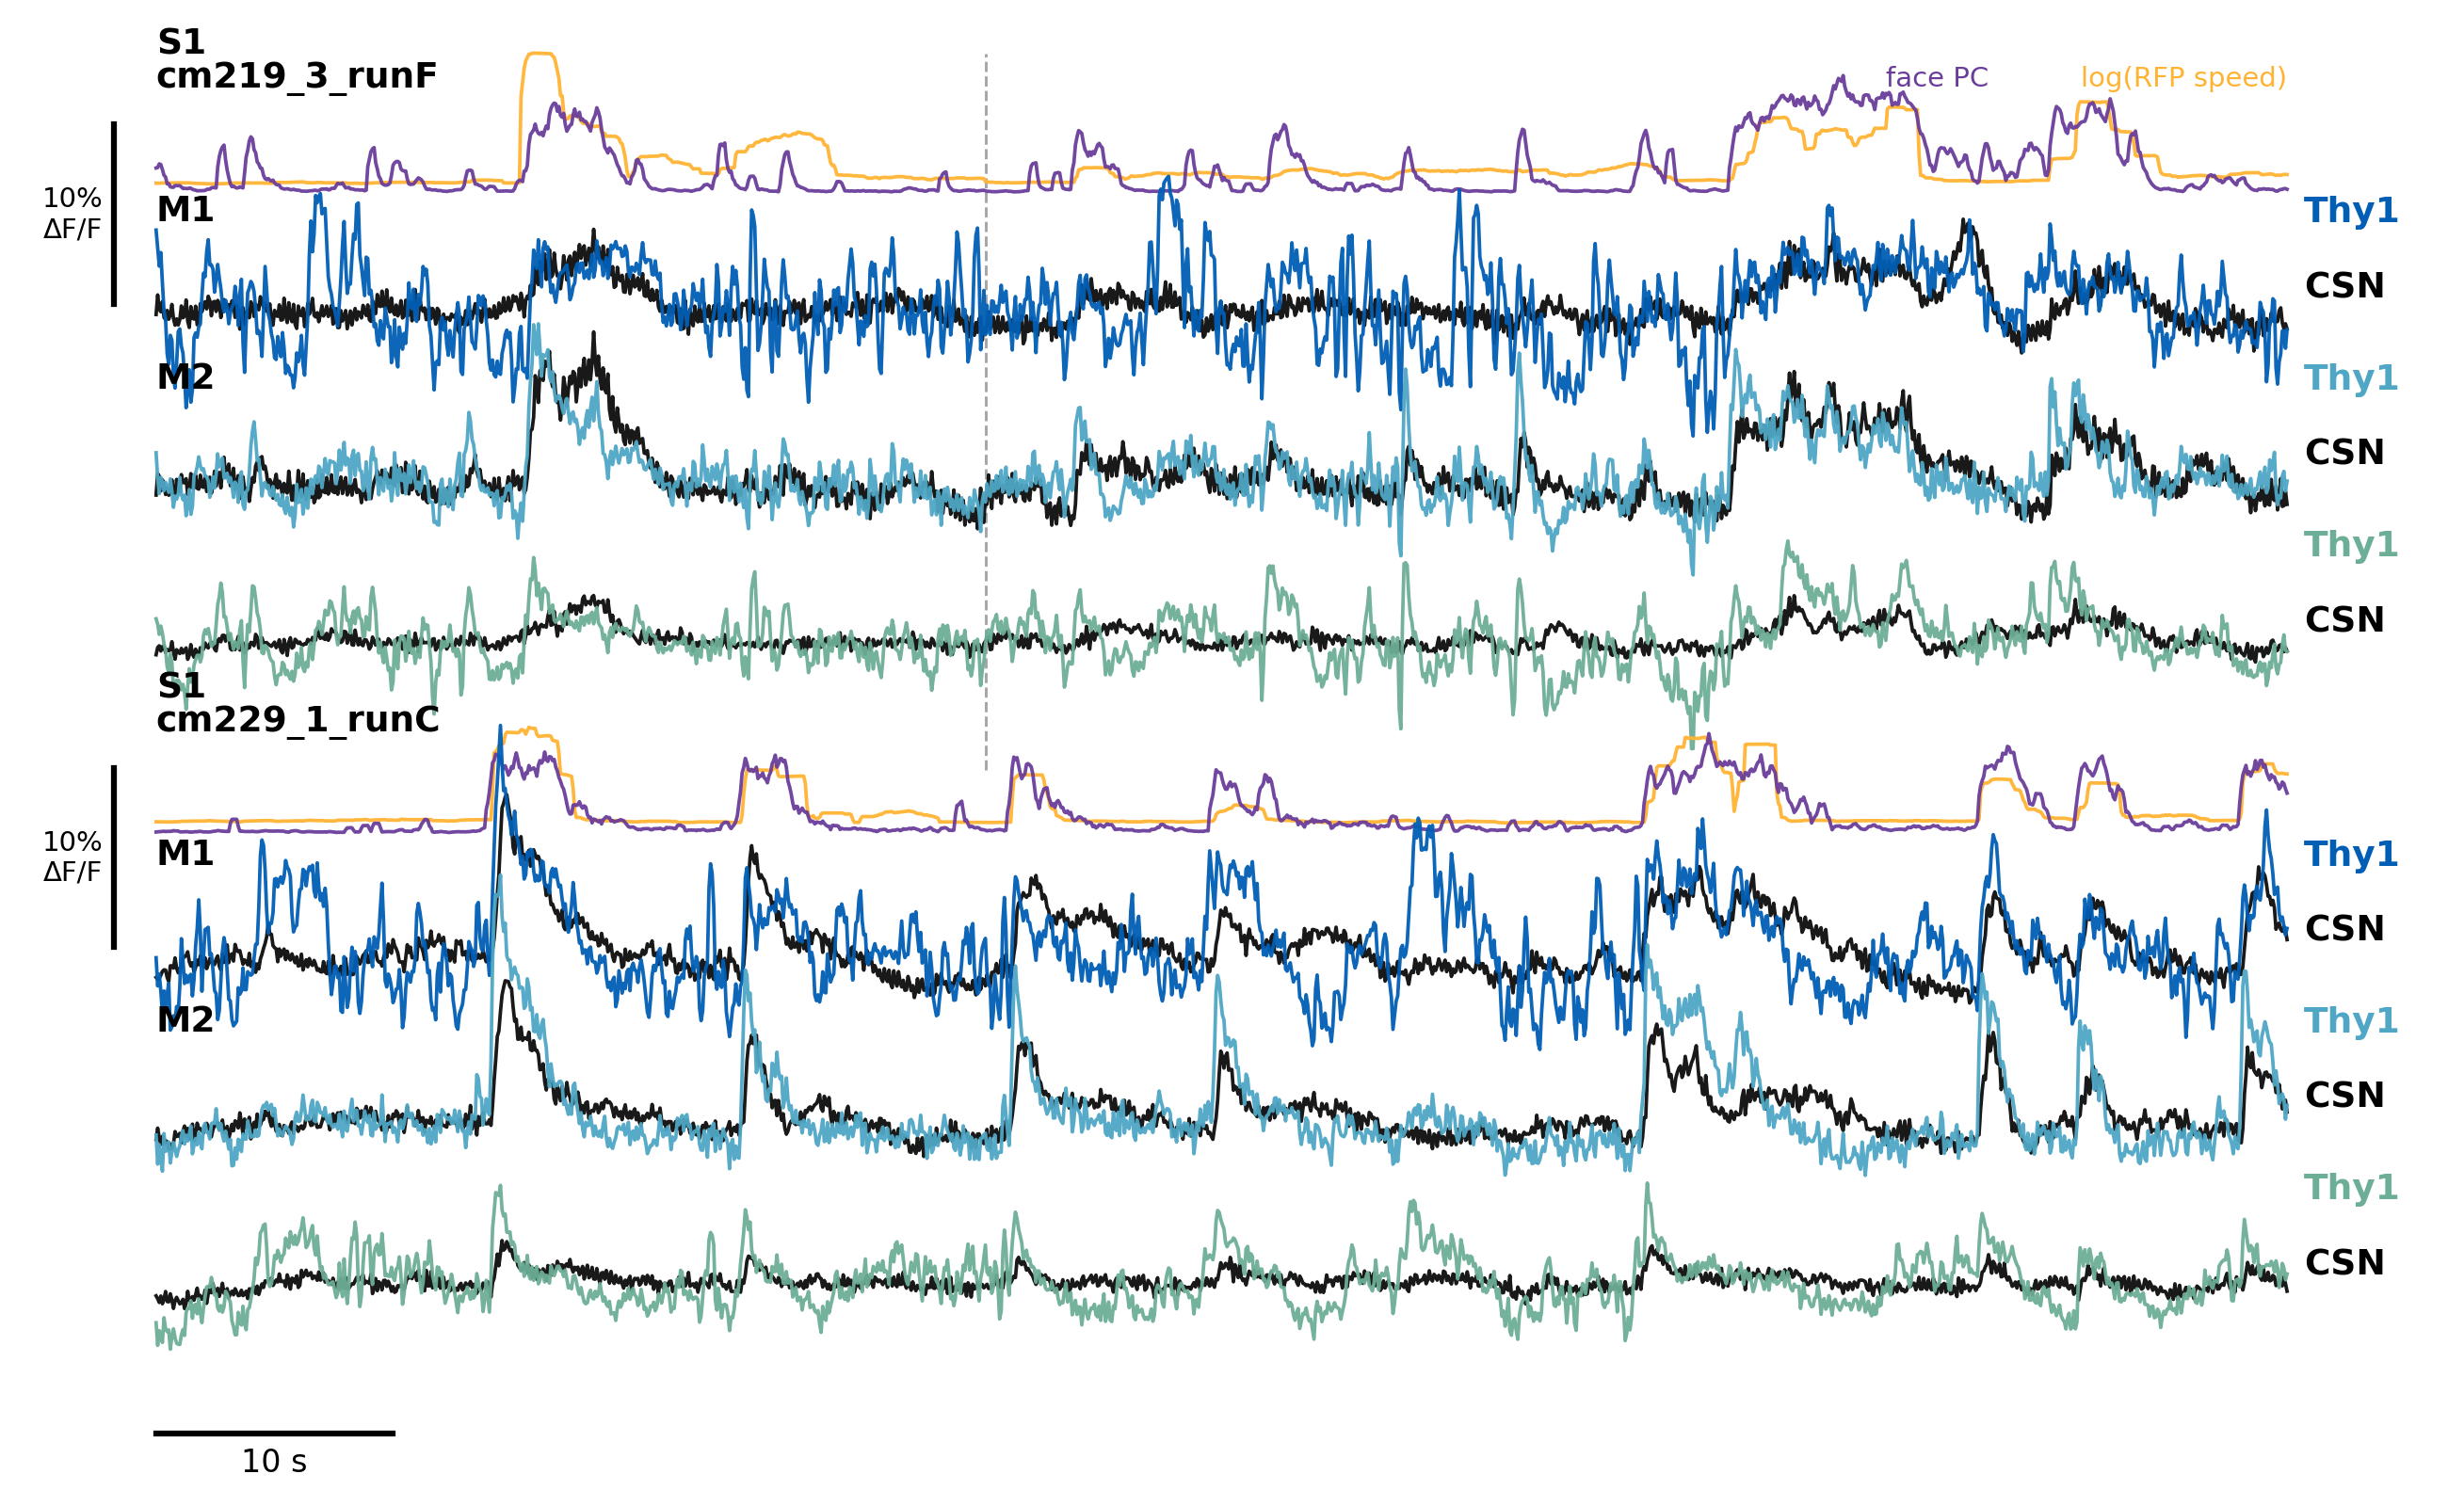

In [10]:
# Cell 5 — Final figure (v8: single panel, S1→M1→M2 order, multi-segment support)
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

thy1_colors = {'RFP_S1': '#015EB5', 'RFP_M1': '#4fa7c5', 'RFP_M2': '#6dae96'}
csn_color   = 'black'
beh_colors  = {'log_RFP_vel': '#ffb332', 'face_pc': '#6A3D9A'}

lw        = 0.9
dff_scale = 0.10

sessions    = [sd1, sd2]
idx_slices  = [idx_slice_1, idx_slice_2]
breaks_list = [breaks_1, breaks_2]

# ----- data range -----
all_neural = []
for sd, idx in zip(sessions, idx_slices):
    for bdp in ['RFP_S1', 'RFP_M1', 'RFP_M2']:
        all_neural.append(sd['jrgeco2plot'][bdp][idx])
        all_neural.append(sd['gcamp2plot'][bdp][idx])
stacked   = np.concatenate(all_neural)
data_min  = np.nanmin(stacked)
data_max  = np.nanmax(stacked)
data_span = data_max - data_min

# ----- spacing knobs -----
row_spacing       = data_span * 0.45
beh_row_offset    = row_spacing * 0.9
gap_between_mice  = row_spacing * 0.5
label_offset      = row_spacing * 0.45

# ----- y offsets (top→bottom per mouse: S1, M1, M2) -----
y_offs = {}
# cm229 on bottom — bottom→top: M2, M1, S1
y_offs[(1, 'RFP_M2')] = 0.0
y_offs[(1, 'RFP_M1')] = 1.0 * row_spacing
y_offs[(1, 'RFP_S1')] = 2.0 * row_spacing
y_offs[(1, 'beh')]    = 2.0 * row_spacing + beh_row_offset
label_y_cm229         = y_offs[(1, 'beh')] + label_offset

# cm219 on top — same internal order
base_top = label_y_cm229 + gap_between_mice
y_offs[(0, 'RFP_M2')] = base_top + 0.0
y_offs[(0, 'RFP_M1')] = base_top + 1.0 * row_spacing
y_offs[(0, 'RFP_S1')] = base_top + 2.0 * row_spacing
y_offs[(0, 'beh')]    = base_top + 2.0 * row_spacing + beh_row_offset
label_y_cm219         = y_offs[(0, 'beh')] + label_offset

# ----- figure -----
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=300)
t    = np.arange(window_length) / FS
xmax = t[-1]

for i_mouse, (sd, idx_slice, breaks) in enumerate(zip(sessions, idx_slices, breaks_list)):
    # --- behavior row ---
    y_beh   = y_offs[(i_mouse, 'beh')]
    log_rfp = sd['behaviors']['log_RFP_vel'][idx_slice] / 50
    face    = sd['behaviors']['face_pc'][idx_slice]     / 50
    ax.plot(t, log_rfp + y_beh, color=beh_colors['log_RFP_vel'], lw=lw, alpha=0.95)
    ax.plot(t, face    + y_beh, color=beh_colors['face_pc'],    lw=lw, alpha=0.95)

    # session label
    label_y = label_y_cm229 if i_mouse == 1 else label_y_cm219
    ax.text(0, label_y, sd['session_name'],
            fontsize=9, fontweight='bold', va='center', ha='left')

    # --- neural rows ---
    for bdp in ['RFP_S1', 'RFP_M1', 'RFP_M2']:
        y0   = y_offs[(i_mouse, bdp)]
        thy1 = sd['jrgeco2plot'][bdp][idx_slice]
        csn  = sd['gcamp2plot'][bdp][idx_slice]

        ax.plot(t, csn  + y0, color=csn_color,        lw=lw, alpha=0.9,  zorder=1)
        ax.plot(t, thy1 + y0, color=thy1_colors[bdp], lw=lw, alpha=0.95, zorder=2)

        # region label at top-left of row
        ax.text(0, y0 + data_max + row_spacing*0.02,
                bdp.split('_')[1],
                fontsize=9, fontweight='bold', va='bottom', ha='left')

        # right-side Thy1 / CSN labels
        ax.text(xmax + xmax*0.008, y0 + row_spacing*0.55, 'Thy1',
                color=thy1_colors[bdp], fontsize=9, va='center', fontweight='bold')
        ax.text(xmax + xmax*0.008, y0 + row_spacing*0.10, 'CSN',
                color=csn_color, fontsize=9, va='center', fontweight='bold')

    # --- segment-break vertical dashed lines (per-mouse span) ---
    mouse_y_bottom = y_offs[(i_mouse, 'RFP_M2')] + data_min
    mouse_y_top    = y_offs[(i_mouse, 'beh')]    + row_spacing * 0.6
    for bx in breaks:
        ax.plot([bx, bx], [mouse_y_bottom, mouse_y_top],
                color='gray', linestyle='--', lw=0.7, alpha=0.7, zorder=0)

# ----- behavior legend (top mouse only) -----
y_legend = y_offs[(0, 'beh')] + row_spacing*0.45
ax.text(xmax,            y_legend, 'log(RFP speed)',
        color=beh_colors['log_RFP_vel'], fontsize=7, ha='right', va='center')
ax.text(xmax - xmax*0.14, y_legend, 'face PC',
        color=beh_colors['face_pc'],     fontsize=7, ha='right', va='center')

# ----- ΔF/F scale bar on each mouse's topmost row (S1 now) -----
bar_x = -xmax * 0.02
for i_mouse in [0, 1]:
    y0 = y_offs[(i_mouse, 'RFP_S1')]
    ax.plot([bar_x, bar_x], [y0, y0 + dff_scale], color='black', lw=1.5)
    ax.text(bar_x - xmax*0.005, y0 + dff_scale/2,
            f'{int(dff_scale*100)}%\nΔF/F',
            fontsize=7, ha='right', va='center')

# ----- 10 s time scale bar (below bottom-most row, cm229 M2) -----
y_timebar = y_offs[(1, 'RFP_M2')] + data_min - row_spacing*0.12
ax.plot([0, 10], [y_timebar, y_timebar], color='black', lw=1.5)
ax.text(5, y_timebar - row_spacing*0.08, '10 s',
        fontsize=8, ha='center', va='top')

# ----- clean axis -----
for s in ('top','right','left','bottom'): ax.spines[s].set_visible(False)
ax.set_xticks([]); ax.set_yticks([])

ax.set_xlim(-xmax*0.06, xmax + xmax*0.07)
ax.set_ylim(y_timebar - row_spacing*0.15, label_y_cm219 + row_spacing*0.2)

plt.savefig('fig5-inset-two-mice.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()